# 04 — Mask R-CNN (torchvision ResNet50-FPN v2)

Padanan ekstraksi otomatis di paper (Tabel 1, Fig. 8, 16–18).

1. Chip 512×512 px dari `interim/ui_rgb.tif`; instance mask dari layer OSM, dirasterisasi saat dibaca.
   Kelas: 1 Bangunan, 2 Jalan (garis di-buffer sesuai lebar), 3 Vegetasi, 4 Air.
   Label bangunan = OSM + Google Open Buildings v3 yang tidak tumpang tindih dengan OSM (`maskrcnn.label_gob`),
   karena OSM tidak lengkap: gedung nyata tanpa label OSM membuat model belajar bahwa atap = latar.
2. Split 80/20 per blok spasial 4×4 chip agar chip latih dan validasi tidak bertetangga. Chip latih diambil
   dengan stride 256 px (overlap 50%) untuk memperbanyak data, tetapi tidak boleh menyentuh blok validasi.
   Augmentasi: rotasi 90° acak + flip.
3. Mask R-CNN pretrained COCO, head diganti untuk 5 kelas (latar + 4).
4. Latih maks. 8 epoch (replikasi paper) dan 25 epoch (pembanding); loss latih/validasi per batch (Fig. 18).
   Bobot yang dipakai = epoch dengan loss validasi terendah (mencegah overfit). Disk hemat: hanya checkpoint
   epoch terakhir (untuk melanjutkan bila terputus) dan bobot terbaik yang disimpan.
5. Precision/Recall/F1 per kelas pada IoU mask ≥ 0,5 (Tabel 1), contoh deteksi (Fig. 16–17).
6. Inferensi seluruh AOI dengan sliding window → poligon gedung; duplikat antar-window dibuang dengan NMS
   (bukan digabung), simplify 0,5 m; raster kelas (Fig. 8).

**Output**: `models/maskrcnn_ui.pt`, `output/dl_buildings.gpkg`, `output/dl_classes.tif`, `output/dl_metrics.csv`.

Butuh GPU CUDA; di CPU training sangat lambat. Hemat memori untuk GPU kecil (mis. 6 GB): input tidak di-upscale
(`min_size=max_size=512`), mixed precision (AMP), batch 1. Bila tetap OOM: restart kernel dulu agar memori lama lepas.

In [1]:
import shutil
import time

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import torch
from rasterio.features import rasterize, shapes
from rasterio.windows import Window
import shapely
from shapely.geometry import box, shape
from shapely.ops import unary_union
from torch import nn
from torchvision.models.detection import maskrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

from ui3d_common import CFG, CRS, interim, model_path, out, road_polygons, savefig

M = CFG["maskrcnn"]
S = M["chip_px"]
CLASSES = ["latar", "bangunan", "jalan", "vegetasi", "air"]
COLORS = np.array([[0, 0, 0], [255, 140, 0], [255, 255, 255], [34, 139, 34], [30, 144, 255]], np.uint8)
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(M["seed"])
print("Device:", DEV)

Device: cuda


## 1. Instance per kelas dan indeks chip

In [2]:
src = rasterio.open(interim("ui_rgb.tif"))
lay = interim("osm_layers.gpkg")
ref = gpd.read_file(out("ref_buildings.gpkg"))
roads = gpd.read_file(lay, layer="roads")
veg = gpd.read_file(lay, layer="vegetation")
water = gpd.read_file(lay, layer="water")

bld_labels = ref.geometry
if M["label_gob"]:
    gob = gpd.read_file(out("gob_buildings.gpkg"))
    hit = gpd.sjoin(gob[["geometry"]].reset_index(drop=True), ref[["geometry"]].reset_index(drop=True),
                    predicate="intersects")
    g_hit = gob.geometry.values[hit.index.values]
    frac = shapely.area(shapely.intersection(g_hit, ref.geometry.values[hit.index_right.values])) / shapely.area(g_hit)
    ov = pd.Series(frac, index=hit.index.values).groupby(level=0).sum()  # fraksi luas GOB yang tertutup OSM
    extra = gob.reset_index(drop=True).drop(index=ov[ov > M["gob_max_overlap"]].index)
    bld_labels = pd.concat([ref.geometry, extra.geometry], ignore_index=True)
    print(f"Label bangunan: {len(ref)} OSM + {len(extra)} GOB v3 (tidak tumpang tindih OSM)")
parts = [(1, bld_labels), (2, road_polygons(roads)), (3, veg.geometry), (4, water.geometry)]
inst = gpd.GeoDataFrame({"cls": np.concatenate([[k] * len(g) for k, g in parts])},
                        geometry=pd.concat([g for _, g in parts], ignore_index=True), crs=CRS)
sidx = inst.sindex


def chip_box(r, c, h=S, w=S):
    return box(*rasterio.windows.bounds(Window(c, r, w, h), src.transform))


B = S * M["block_chips"]


def grid(stride):
    df = pd.DataFrame([(r, c) for r in range(0, src.height - S + 1, stride) for c in range(0, src.width - S + 1, stride)],
                      columns=["row", "col"])
    df["n_inst"] = [len(sidx.query(chip_box(r, c), predicate="intersects")) for r, c in zip(df.row, df.col)]
    df["nodata_frac"] = [(src.read(1, window=Window(c, r, S, S)) == 0).mean() for r, c in zip(df.row, df.col)]
    return df[(df.n_inst > 0) & (df.nodata_frac < 0.5)].reset_index(drop=True)


def blocks_of(r, c):
    """Semua blok spasial yang disentuh chip (r, c)."""
    return {(i, j) for i in range(r // B, (r + S - 1) // B + 1) for j in range(c // B, (c + S - 1) // B + 1)}


aligned = grid(S)
rng = np.random.default_rng(M["seed"])
blocks = sorted({(r // B, c // B) for r, c in zip(aligned.row, aligned.col)})
val_blocks = {blocks[k] for k in rng.choice(len(blocks), max(1, round(len(blocks) * M["val_fraction"])), replace=False)}
val = aligned[[blocks_of(r, c) <= val_blocks for r, c in zip(aligned.row, aligned.col)]].assign(split="val")
dense = grid(M["train_stride_px"])
train_ = dense[[not (blocks_of(r, c) & val_blocks) for r, c in zip(dense.row, dense.col)]].assign(split="train")
idx = pd.concat([train_, val], ignore_index=True)
idx.to_csv(interim("chips_index.csv"), index=False)
print(idx.split.value_counts().to_dict())

# Area validasi (dipakai notebook 05 agar evaluasi footprint Mask R-CNN tidak memakai area latih).
val_area = unary_union([chip_box(r, c) for r, c in idx.loc[idx.split == "val", ["row", "col"]].values])
gpd.GeoDataFrame(geometry=[val_area], crs=CRS).to_file(interim("dl_val_area.gpkg"), layer="val_area")

Label bangunan: 995 OSM + 355 GOB v3 (tidak tumpang tindih OSM)


{'train': 473, 'val': 39}


## Dataset: rasterisasi instance per chip

In [3]:
class ChipDS(torch.utils.data.Dataset):
    def __init__(self, df, train):
        self.df, self.train = df.reset_index(drop=True), train

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        r, c = int(self.df.row[i]), int(self.df.col[i])
        win = Window(c, r, S, S)
        tr = src.window_transform(win)
        img = src.read(window=win)
        masks, labels = [], []
        for j in sidx.query(chip_box(r, c), predicate="intersects"):
            m = rasterize([(inst.geometry.iloc[j], 1)], out_shape=(S, S), transform=tr, dtype="uint8")
            if m.sum() >= M["min_pixels"]:
                masks.append(m)
                labels.append(inst.cls.iloc[j])
        masks = np.array(masks, np.uint8).reshape(-1, S, S)
        if self.train:  # augmentasi: rotasi 90° acak + flip horizontal
            k = int(torch.randint(4, (1,)))
            img, masks = np.rot90(img, k, (1, 2)), np.rot90(masks, k, (1, 2))
            if torch.rand(1) < 0.5:
                img, masks = img[:, :, ::-1], masks[:, :, ::-1]
        boxes = []
        for m in masks:
            ys, xs = np.where(m)
            boxes.append([xs.min(), ys.min(), xs.max() + 1, ys.max() + 1])
        target = {"boxes": torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4),
                  "labels": torch.tensor(labels, dtype=torch.int64),
                  "masks": torch.from_numpy(masks.copy())}
        return torch.from_numpy(img.copy()).float() / 255, target


def collate(b):
    return tuple(zip(*b))


ds_train, ds_val = ChipDS(idx[idx.split == "train"], True), ChipDS(idx[idx.split == "val"], False)
# num_workers=0: handle rasterio tidak aman dibagi antar proses.
dl_train = torch.utils.data.DataLoader(ds_train, batch_size=M["batch_size"], shuffle=True, collate_fn=collate)
dl_val = torch.utils.data.DataLoader(ds_val, batch_size=M["batch_size"], shuffle=False, collate_fn=collate)
print(len(ds_train), "chip latih;", len(ds_val), "chip validasi")

473 chip latih; 39 chip validasi


## 3–4. Model dan training (8 vs 25 epoch)

In [4]:
def build_model():
    # default torchvision memperbesar gambar ke 800 px; chip 512 dipakai apa adanya agar hemat memori GPU
    m = maskrcnn_resnet50_fpn_v2(weights="DEFAULT", min_size=S, max_size=S)
    m.roi_heads.box_predictor = FastRCNNPredictor(1024, len(CLASSES))
    m.roi_heads.mask_predictor = MaskRCNNPredictor(256, 256, len(CLASSES))
    return m.to(DEV)


def to_dev(imgs, tgs):
    return [i.to(DEV) for i in imgs], [{k: v.to(DEV) for k, v in t.items()} for t in tgs]


def val_by_epoch(log):
    return pd.DataFrame(log).query("split == 'val'").groupby("epoch").loss.mean()


def train(epochs):
    tag = f"e{epochs}"
    final, log_path = model_path(f"maskrcnn_ui_{tag}.pt"), model_path(f"loss_{tag}.csv")
    best_path = model_path(f"maskrcnn_ui_{tag}_best.pt")
    m = build_model()
    if final.exists():
        m.load_state_dict(torch.load(final, map_location=DEV))
        log = pd.read_csv(log_path)
        return m, log, int(val_by_epoch(log).idxmin())
    use_amp = DEV.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    params = [p for p in m.parameters() if p.requires_grad]
    opt = torch.optim.SGD(params, lr=M["lr"], momentum=0.9, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=max(1, epochs * 2 // 3), gamma=0.1)
    start, log = 0, []
    ckpts = sorted(model_path(".").glob(f"maskrcnn_ui_{tag}_ep*.pt"), key=lambda p: int(p.stem.split("_ep")[1]))
    if ckpts:  # lanjutkan dari checkpoint terakhir
        ck = torch.load(ckpts[-1], map_location=DEV, weights_only=False)
        m.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
        start, log = ck["epoch"], ck["log"]
        print("Lanjut dari", ckpts[-1].name)
    for ep in range(start, epochs):
        t0 = time.time()
        m.train()
        for b, (imgs, tgs) in enumerate(dl_train):
            with torch.autocast(DEV.type, dtype=torch.float16, enabled=use_amp):
                loss = sum(m(*to_dev(imgs, tgs)).values())
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            log.append(dict(epoch=ep + 1, batch=b, split="train", loss=loss.item()))
        # Loss validasi: torchvision hanya mengembalikan loss di mode train; BatchNorm dibekukan agar tidak bocor.
        for mod in m.modules():
            if isinstance(mod, nn.BatchNorm2d):
                mod.eval()
        with torch.no_grad():
            for b, (imgs, tgs) in enumerate(dl_val):
                with torch.autocast(DEV.type, dtype=torch.float16, enabled=use_amp):
                    loss = sum(m(*to_dev(imgs, tgs)).values())
                log.append(dict(epoch=ep + 1, batch=b, split="val", loss=loss.item()))
        sched.step()
        if val_by_epoch(log).idxmin() == ep + 1:
            torch.save(m.state_dict(), best_path)
        ck = model_path(f"maskrcnn_ui_{tag}_ep{ep + 1}.pt")
        torch.save(dict(model=m.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(), epoch=ep + 1, log=log), ck)
        for old in model_path(".").glob(f"maskrcnn_ui_{tag}_ep*.pt"):
            if old != ck:
                old.unlink()
        ep_log = pd.DataFrame(log).query("epoch == @ep + 1").groupby("split").loss.mean()
        print(f"[{tag}] epoch {ep + 1}/{epochs} train {ep_log['train']:.3f} val {ep_log['val']:.3f} ({time.time() - t0:.0f} s)")
    best_ep = int(val_by_epoch(log).idxmin())
    m.load_state_dict(torch.load(best_path, map_location=DEV))
    torch.save(m.state_dict(), final)
    log = pd.DataFrame(log)
    log.to_csv(log_path, index=False)
    print(f"[{tag}] bobot dipakai: epoch {best_ep} (loss validasi terendah)")
    return m, log, best_ep


models, logs, best_eps = {}, {}, {}
for e in M["epochs"]:
    models[e], logs[e], best_eps[e] = train(e)
    models[e].cpu()  # lepas memori GPU sebelum model berikutnya dilatih
    torch.cuda.empty_cache()

[e8] epoch 1/8 train 2.338 val 2.390 (92 s)


[e8] epoch 2/8 train 2.080 val 2.345 (92 s)


[e8] epoch 3/8 train 1.997 val 2.211 (92 s)


[e8] epoch 4/8 train 1.948 val 2.630 (93 s)


[e8] epoch 5/8 train 1.902 val 2.371 (93 s)


...

[e25] epoch 22/25 train 1.361 val 2.849 (95 s)


[e25] epoch 23/25 train 1.343 val 2.875 (95 s)


[e25] epoch 24/25 train 1.310 val 3.083 (95 s)


[e25] epoch 25/25 train 1.299 val 2.960 (96 s)


[e25] bobot dipakai: epoch 5 (loss validasi terendah)


### Kurva loss per batch (setara Fig. 18)

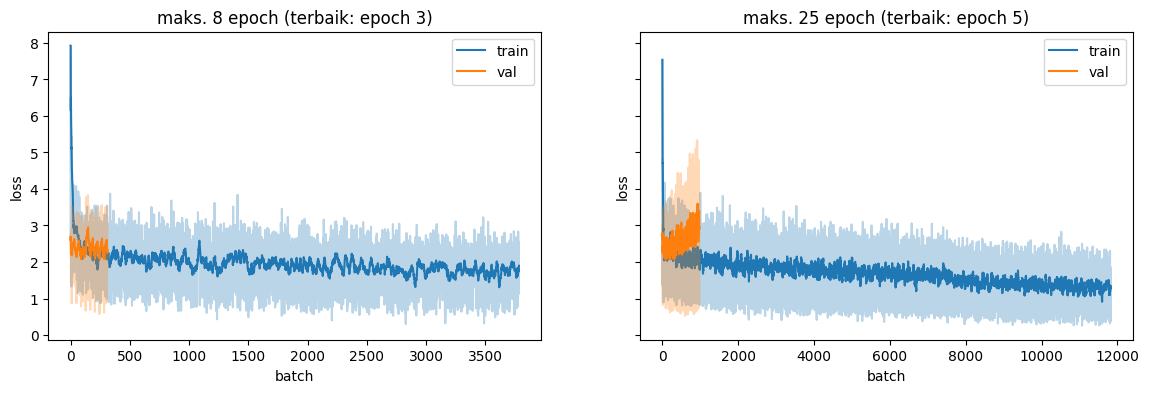

In [5]:
fig, ax = plt.subplots(1, len(logs), figsize=(7 * len(logs), 4), sharey=True)
for a, (e, lg) in zip(np.atleast_1d(ax), logs.items()):
    for split, col in (("train", "tab:blue"), ("val", "tab:orange")):
        s = lg[lg.split == split].loss.reset_index(drop=True)
        a.plot(s, color=col, alpha=0.3)
        a.plot(s.rolling(20, min_periods=1).mean(), color=col, label=split)
    a.set(title=f"maks. {e} epoch (terbaik: epoch {best_eps[e]})", xlabel="batch", ylabel="loss")
    a.legend()
savefig(fig, "fig18_loss.png")
plt.show()

## 5. Precision, Recall, F1 per kelas (IoU mask ≥ 0,5)

In [6]:
@torch.no_grad()
def predict(m, img):
    m.to(DEV).eval()
    p = m([img.to(DEV)])[0]
    keep = p["scores"] >= M["score_threshold"]
    order = torch.argsort(p["scores"][keep], descending=True)
    return ((p["masks"][keep][order, 0] > 0.5).cpu().numpy(), p["labels"][keep][order].cpu().numpy(),
            p["scores"][keep][order].cpu().numpy())


def evaluate(m):
    cnt = {k: dict(TP=0, FP=0, FN=0) for k in range(1, len(CLASSES))}
    for i in range(len(ds_val)):
        img, tg = ds_val[i]
        pm, pl, _ = predict(m, img)
        gm, gl = tg["masks"].numpy().astype(bool), tg["labels"].numpy()
        for k in cnt:
            P, G = pm[pl == k], gm[gl == k]
            used, tp = np.zeros(len(G), bool), 0
            for pmask in P:  # greedy berdasarkan skor tertinggi
                if not len(G):
                    break
                iou = (G & pmask).sum((1, 2)) / np.maximum((G | pmask).sum((1, 2)), 1)
                iou[used] = 0
                j = iou.argmax()
                if iou[j] >= M["iou_threshold"]:
                    used[j], tp = True, tp + 1
            cnt[k]["TP"] += tp; cnt[k]["FP"] += len(P) - tp; cnt[k]["FN"] += len(G) - tp
    rows = []
    for k, c in cnt.items():
        p = c["TP"] / max(c["TP"] + c["FP"], 1)
        r = c["TP"] / max(c["TP"] + c["FN"], 1)
        rows.append(dict(kelas=CLASSES[k], **c, precision=p, recall=r, f1=2 * p * r / max(p + r, 1e-9)))
    return pd.DataFrame(rows)


metrics = pd.concat([evaluate(m).assign(epochs=e, best_epoch=best_eps[e]) for e, m in models.items()],
                    ignore_index=True).round(3)
paper = {"bangunan": (0.78, 0.86, 0.82), "jalan": (0.62, 0.875, 0.73), "vegetasi": (0.89, 0.96, 0.93)}
metrics["paper_P_R_F1"] = metrics.kelas.map(paper)
metrics.to_csv(out("dl_metrics.csv"), index=False)
metrics

,kelas,TP,FP,FN,precision,recall,f1,epochs,best_epoch,paper_P_R_F1
0,bangunan,77,142,339,0.352,0.185,0.243,8,3,"(0.78, 0.86, 0.82)"
1,jalan,0,58,349,0.000,0.000,0.000,8,3,"(0.62, 0.875, 0.73)"
2,vegetasi,12,58,87,0.171,0.121,0.142,8,3,"(0.89, 0.96, 0.93)"
3,air,3,9,14,0.250,0.176,0.207,8,3,NaN
4,bangunan,77,127,339,0.377,0.185,0.248,25,5,"(0.78, 0.86, 0.82)"
5,jalan,1,82,348,0.012,0.003,0.005,25,5,"(0.62, 0.875, 0.73)"
6,vegetasi,15,66,84,0.185,0.152,0.167,25,5,"(0.89, 0.96, 0.93)"
7,air,5,4,12,0.556,0.294,0.385,25,5,NaN


In [7]:
# Model terbaik (F1 bangunan) dipakai untuk inferensi dan disalin ke models/maskrcnn_ui.pt.
best_e = int(metrics[metrics.kelas == "bangunan"].sort_values("f1").epochs.iloc[-1])
best = models[best_e]
shutil.copy(model_path(f"maskrcnn_ui_e{best_e}.pt"), model_path("maskrcnn_ui.pt"))
print("Model terbaik:", best_e, "epoch")

Model terbaik: 25 epoch


### Contoh deteksi (setara Fig. 16–17): referensi OSM vs prediksi

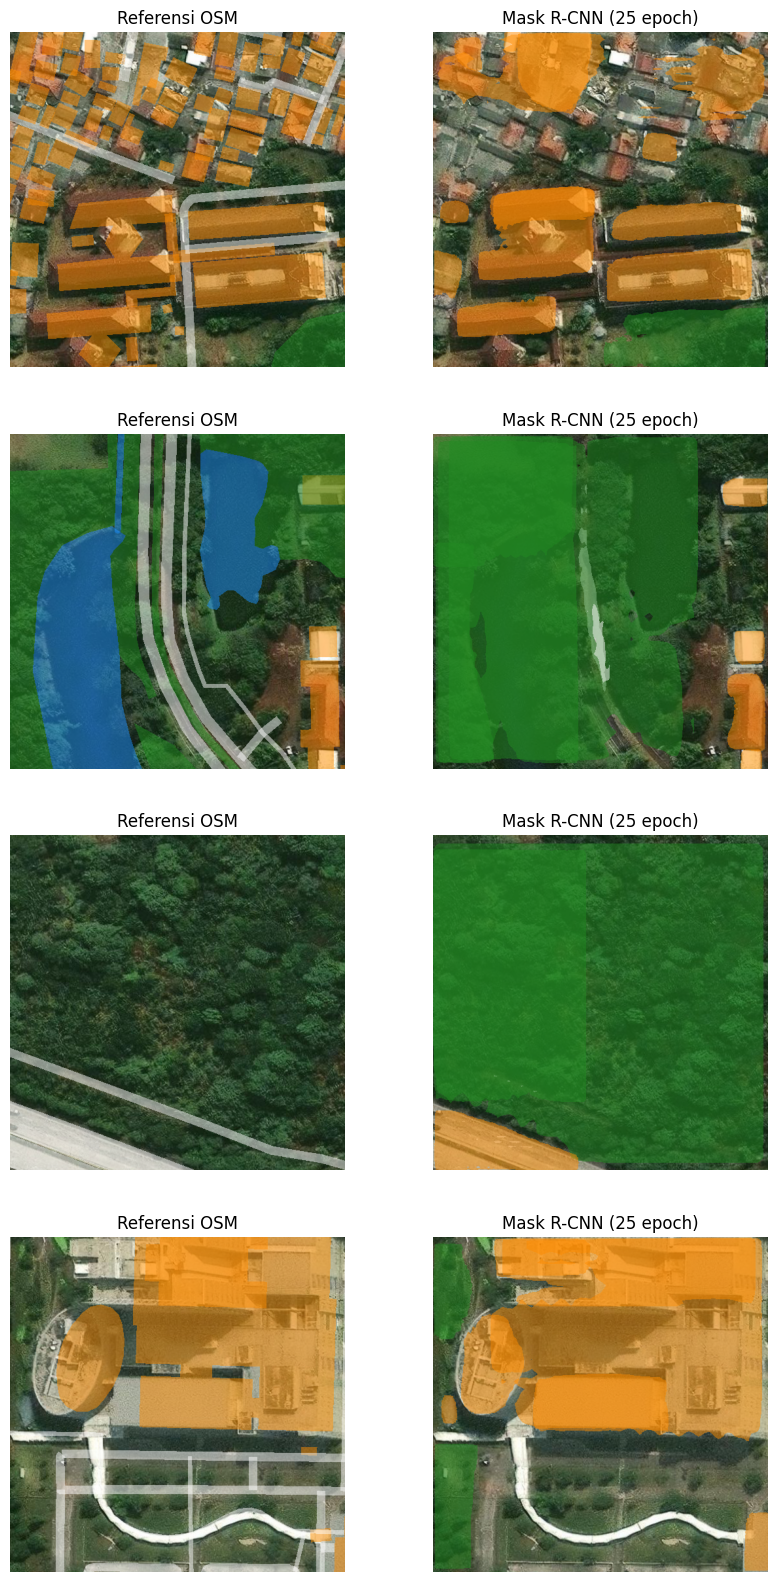

In [8]:
def overlay(img, masks, labels):
    o = img.copy()
    for m, k in zip(masks, labels):
        o[m] = (0.5 * o[m] + 0.5 * COLORS[k]).astype(np.uint8)
    return o


sel = np.linspace(0, len(ds_val) - 1, min(4, len(ds_val))).astype(int)
fig, axs = plt.subplots(len(sel), 2, figsize=(10, 5 * len(sel)), squeeze=False)
for row, i in zip(axs, sel):
    img, tg = ds_val[i]
    rgb = (img.permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    pm, pl, _ = predict(best, img)
    row[0].imshow(overlay(rgb, tg["masks"].numpy().astype(bool), tg["labels"].numpy())); row[0].set_title("Referensi OSM")
    row[1].imshow(overlay(rgb, pm, pl)); row[1].set_title(f"Mask R-CNN ({best_e} epoch)")
    for a in row:
        a.axis("off")
savefig(fig, "fig16_17_contoh_deteksi.png")
plt.show()

## 6. Inferensi seluruh AOI (sliding window)

Raster kelas: tiap piksel diberi kelas instance dengan skor tertinggi. Poligon gedung dari mask instance.
Duplikat antar-window dibuang dengan NMS: urut skor, buang poligon yang IoU ≥ 0,5 atau ≥ 70% luasnya
tertutup poligon berskor lebih tinggi. Gedung berdempetan tidak lagi dilebur jadi satu.

In [9]:
step = S - M["overlap_px"]
cls_r = np.zeros((src.height, src.width), np.uint8)
score_r = np.zeros((src.height, src.width), np.float32)
polys = []
t0 = time.time()
for r in range(0, src.height, step):
    for c in range(0, src.width, step):
        win = Window(c, r, min(S, src.width - c), min(S, src.height - r))
        img = src.read(window=win)
        if img.max() == 0:
            continue
        pm, pl, ps = predict(best, torch.from_numpy(img).float() / 255)
        sl = (slice(r, r + win.height), slice(c, c + win.width))
        wtr = src.window_transform(win)
        for m, k, s in zip(pm, pl, ps):
            upd = m & (s > score_r[sl])
            cls_r[sl][upd], score_r[sl][upd] = k, s
            if k == 1:
                polys += [(shape(g), s) for g, _ in shapes(m.astype(np.uint8), mask=m, transform=wtr)]
print(f"Inferensi {time.time() - t0:.0f} s")

prof = dict(driver="GTiff", height=src.height, width=src.width, count=1, dtype="uint8", crs=CRS,
            transform=src.transform, compress="deflate", tiled=True)
with rasterio.open(out("dl_classes.tif"), "w", **prof) as d:
    d.write(cls_r, 1)

cand = gpd.GeoDataFrame({"score": [s for _, s in polys]}, geometry=[g.buffer(0) for g, _ in polys], crs=CRS)
cand = cand[cand.area >= CFG["footprint"]["min_area_m2"]].sort_values("score", ascending=False).reset_index(drop=True)
geoms = cand.geometry.values
tree, keep = shapely.STRtree(geoms), np.ones(len(cand), bool)
for i, g in enumerate(geoms):
    if not keep[i]:
        continue
    for j in tree.query(g, predicate="intersects"):
        if j > i and keep[j]:
            inter = g.intersection(geoms[j]).area
            if inter / g.union(geoms[j]).area >= 0.5 or inter / min(g.area, geoms[j].area) >= 0.7:
                keep[j] = False
dl_bld = cand[keep].copy()
dl_bld["geometry"] = dl_bld.simplify(CFG["maskrcnn"]["simplify_m"])
dl_bld = dl_bld.reset_index(drop=True)
print(f"NMS: {len(cand)} kandidat → {len(dl_bld)} gedung")
dl_bld["footprint_source"] = f"MaskRCNN_e{best_e}"
dl_bld.to_file(out("dl_buildings.gpkg"), layer="dl_buildings")
print(len(dl_bld), "gedung hasil Mask R-CNN")

Inferensi 49 s


NMS: 2705 kandidat → 1803 gedung
1803 gedung hasil Mask R-CNN


### Raster klasifikasi AOI (setara Fig. 8)

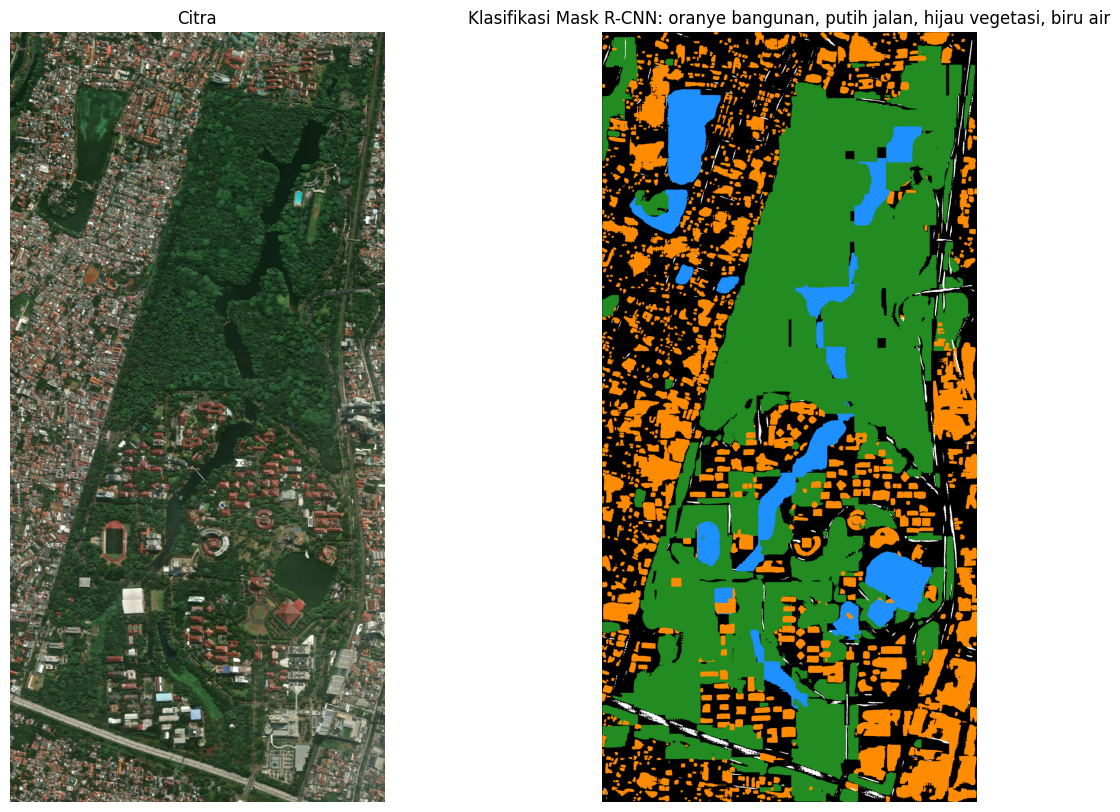

In [10]:
f = max(1, src.width // 1500)
fig, ax = plt.subplots(1, 2, figsize=(14, 10))
ax[0].imshow(src.read(out_shape=(3, src.height // f, src.width // f)).transpose(1, 2, 0))
ax[0].set_title("Citra")
ax[1].imshow(COLORS[cls_r[::f, ::f]])
ax[1].set_title("Klasifikasi Mask R-CNN: oranye bangunan, putih jalan, hijau vegetasi, biru air")
for a in ax:
    a.axis("off")
savefig(fig, "fig08_klasifikasi.png")
plt.show()